In [2]:
import numpy as np
import matplotlib.pyplot as plt
import funky_functions as funk
from IPython.display import Audio, display

Trying to copy what i did at the end of assignment 2

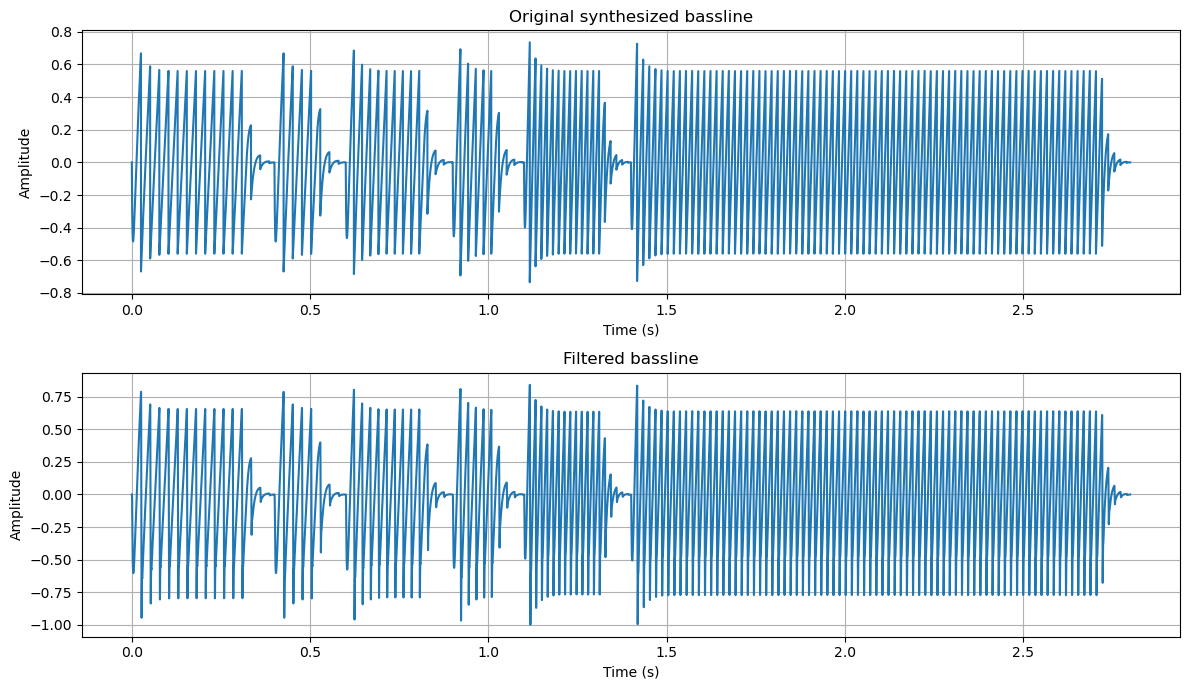

In [3]:
# First six bass notes
fs = 44100
amplitude = 0.8
BPM = 139

# MIDI note numbers
midi_notes = np.array([27, 27, 29, 30, 35, 34])

# Convert MIDI to frequencies
frequencies = 440 * 2 ** ((midi_notes - 69) / 12)

# Note durations in beats
note_beats = np.array([1, 0.5, 0.75, 0.5, 0.75, 3])

# Convert beats to seconds
# durations = note_beats * (60 / BPM)

durations = np.array([0.4, 0.2, 0.3, 0.2, 0.3, 1.4])

# ADSR settings
attack = 0.01
decay = 0.10
sustain = 0.7
release = 0.08

curve = 'exp'

# Generate the six notes
bassline = np.array([])

for k in range(len(midi_notes)):

    # Generate waveform
    t, wave = funk.generate_wave(
        amplitude, frequencies[k], 0, fs,
        durations[k], 'saw'
    )

    # Generate ADSR envelope
    envelope = funk.ADSR_envelope(
        fs, durations[k], attack, decay,
        sustain, release, curve
    )

    # Apply envelope
    note = wave * envelope

    # Concatenate notes
    bassline = np.concatenate((bassline, note))


# Apply low-pass filter
filtered_bass = funk.apply_filter(
    bassline, fs, 'LP', 500, 4
)

# Normalize
filtered_bass = filtered_bass / np.max(np.abs(filtered_bass))

# Time vector
time = np.arange(len(filtered_bass)) / fs


# Plot
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(time, bassline)
plt.title('Original synthesized bassline')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, filtered_bass)
plt.title('Filtered bassline')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)

plt.tight_layout()
plt.show()


# Playback
display(Audio(filtered_bass, rate=fs))
